# ITCS 6169/8169 — Computer Vision
## Assignment 3: One-shot Image Classification

---

Assignments 1 and 2 explored supervised and self-supervised learning with limited labeled data. This assignment asks a harder question:

**Can we achieve high image classification accuracy using only one labeled training example per class?**

Same 2,400-image, 16-class scene dataset, but only **one labeled training image per class (16 images in total)** may be used.

### Rule followed in this notebook
- **Labeled data:** exactly 16 support images (one per class), chosen by a fixed seed and copied to `support/`. No other training label is ever read.
- **Allowed (per assignment hints):** foundation models (CLIP, SigLIP, DINOv2) and test-time adaptation.
- Every number is produced by this notebook, top to bottom, with a fixed seed. Environment versions are written to `results/env.json`.

### Workflow
Built stage by stage, same as the earlier assignments: get **Approach 1 (zero-shot text baseline)** working and record its numbers first, then add the next approach as a new section, adding a row to the "Beat the baseline" table each time.

In [6]:
import sys
import torch
import torchvision

print("=== Environment Check ===")
print(f"Python version:     {sys.version}")
print(f"PyTorch version:    {torch.__version__}")
print(f"Torchvision version:{torchvision.__version__}")
print(f"CUDA available:     {torch.cuda.is_available()}")
print(f"PyTorch built with CUDA: {torch.version.cuda}")

if torch.cuda.is_available():
    print(f"GPU device:         {torch.cuda.get_device_name(0)}")
    print(f"GPU count:          {torch.cuda.device_count()}")
    print(f"CUDA capability:    {torch.cuda.get_device_capability(0)}")
    print(f"Total GPU memory:   {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("WARNING: CUDA not available — everything will run on CPU (much slower).")

=== Environment Check ===
Python version:     3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
PyTorch version:    2.12.0.dev20260408+cu128
Torchvision version:0.27.0.dev20260407+cu128
CUDA available:     True
PyTorch built with CUDA: 12.8
GPU device:         NVIDIA GeForce RTX 5060 Laptop GPU
GPU count:          1
CUDA capability:    (12, 0)
Total GPU memory:   8.55 GB


In [4]:
# Extra dependencies for the foundation models (CLIP / SigLIP via open_clip).
%pip install -q open_clip_torch transformers sentencepiece protobuf

Note: you may need to restart the kernel to use updated packages.


In [7]:
from pathlib import Path
import os, re, json, random, time, shutil, platform

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn.functional as F
import open_clip
import transformers

print(f"PyTorch version: {torch.__version__}")
print(f"open_clip version: {open_clip.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.12.0.dev20260408+cu128
open_clip version: 4.2.2
CUDA available: True


In [ ]:
# Optional: mount Google Drive when running in Colab.
# Skip this cell if you are running locally or on another server.
try:
    from google.colab import drive
    drive.mount('/content/gdrive')
except ImportError:
    print("Not running in Google Colab; Drive mount skipped.")

## 1. Set your working directory

Same dataset layout as Assignments 1 and 2:

```text
data/
  train/
    class_1/
    ...
  test/
    class_1/
    ...
```

Update `PROJECT_ROOT` below if your layout differs.

In [8]:
# CHANGE THIS PATH to your own assignment directory if needed.
PROJECT_ROOT = Path('.')
DATA_ROOT = PROJECT_ROOT / 'data'
TRAIN_ROOT = DATA_ROOT / 'train'
TEST_ROOT = DATA_ROOT / 'test'
EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

print('Project root:', PROJECT_ROOT.resolve())
print('Training data:', TRAIN_ROOT)
print('Testing data:', TEST_ROOT)

Project root: C:\Users\omcka\Downloads\CV\Assignment 3
Training data: data\train
Testing data: data\test


In [9]:
# Sanity check: confirm both splits are present and have the same 16 class folders.
for folder, path in [('train', TRAIN_ROOT), ('test', TEST_ROOT)]:
    if path.exists():
        subdirs = sorted(d.name for d in path.iterdir() if d.is_dir())
        print(f"{folder}: {len(subdirs)} subfolders -> {subdirs}")
    else:
        print(f"{folder}: NOT FOUND")

classes = sorted(d.name for d in TRAIN_ROOT.iterdir() if d.is_dir())
assert classes == sorted(d.name for d in TEST_ROOT.iterdir() if d.is_dir()), 'train/test class folders differ'
assert len(classes) == 16, f'expected 16 classes, found {len(classes)}'

train: 16 subfolders -> ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']
test: 16 subfolders -> ['Bedroom', 'Coast', 'Flower', 'Forest', 'Highway', 'Industrial', 'InsideCity', 'Kitchen', 'LivingRoom', 'Mountain', 'Office', 'OpenCountry', 'Store', 'Street', 'Suburb', 'TallBuilding']


## 2. Reproducibility and device

A fixed seed makes the result reproducible. Exact GPU reproducibility is not guaranteed across hardware/software versions, so the environment and seed are saved to `results/env.json`, and package versions are pinned to `requirements.txt` at the end of this section.

In [10]:
SEED = 0

def set_random_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_random_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float16 if device.type == 'cuda' else torch.float32
print('Using device:', device)

ENV = {'python': platform.python_version(), 'torch': torch.__version__, 'torchvision': torchvision.__version__,
       'open_clip': open_clip.__version__, 'transformers': transformers.__version__,
       'gpu': torch.cuda.get_device_name(0) if device.type == 'cuda' else None, 'seed': SEED}
Path('results').mkdir(exist_ok=True)
json.dump(ENV, open('results/env.json', 'w'), indent=1)
print(ENV)

Using device: cuda
{'python': '3.12.10', 'torch': '2.12.0.dev20260408+cu128', 'torchvision': '0.27.0.dev20260407+cu128', 'open_clip': '4.2.2', 'transformers': '5.22.2', 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU', 'seed': 0}


In [11]:
import importlib.metadata as importlib_metadata
pkgs = ['torch', 'torchvision', 'open_clip_torch', 'transformers', 'sentencepiece', 'protobuf', 'numpy', 'pillow', 'matplotlib']
with open('requirements.txt', 'w') as f:
    for p in pkgs:
        try: f.write(f'{p}=={importlib_metadata.version(p)}\n')
        except Exception: pass
print(open('requirements.txt').read())

torch==2.12.0.dev20260408+cu128
torchvision==0.27.0.dev20260407+cu128
open_clip_torch==4.2.2
transformers==5.22.2
sentencepiece==0.2.1
protobuf==7.36.2
numpy==1.26.4
pillow==12.1.1
matplotlib==3.9.2



## 3. Loading the data: exactly ONE labeled image per class

The 16 support images are drawn at random (seeded per class) from `data/train/<class>/` and copied to `support/`. **Nothing else from the training folder is read.** The test set is used for evaluation only.

Class folder names are turned into prompt-ready names (`humanize`); edit `CLASS_NAME_OVERRIDE` if a name reads badly.

In [12]:
def list_imgs(folder):
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(EXT))

def humanize(c):
    c = re.sub(r'(?<=[a-z])(?=[A-Z])', ' ', c)
    return c.replace('_', ' ').replace('-', ' ').lower().strip()

CLASS_NAME_OVERRIDE = {}          # e.g. {'Mountain': 'mountain landscape'}
CLASS_NAME = {c: CLASS_NAME_OVERRIDE.get(c, humanize(c)) for c in classes}
names = [CLASS_NAME[c] for c in classes]
num_classes = len(classes)
print(names)

def choose_support(seed):
    # one image per class, random but fixed by (seed, class); no labels beyond its own folder are used
    return [TRAIN_ROOT / c / random.Random(f'{seed}-{c}').choice(list_imgs(TRAIN_ROOT / c)) for c in classes]

load = lambda p: Image.open(p).convert('RGB')
support_paths = choose_support(SEED)
assert len(support_paths) == num_classes == 16

shutil.rmtree('support', ignore_errors=True); Path('support').mkdir()
for c, p in zip(classes, support_paths):
    shutil.copy(p, Path('support') / f'{c}__{p.name}')
json.dump({'seed': SEED, 'support': [p.as_posix() for p in support_paths]}, open('support/support_list.json', 'w'), indent=1)

test_paths, test_y = [], []
for i, c in enumerate(classes):
    for f in list_imgs(TEST_ROOT / c):
        test_paths.append(TEST_ROOT / c / f); test_y.append(i)
test_y = torch.tensor(test_y)
test_imgs = [load(p) for p in test_paths]
print('Labeled training images used:', len(support_paths))
print('Test images:', len(test_imgs))

['bedroom', 'coast', 'flower', 'forest', 'highway', 'industrial', 'inside city', 'kitchen', 'living room', 'mountain', 'office', 'open country', 'store', 'street', 'suburb', 'tall building']
Labeled training images used: 16
Test images: 400


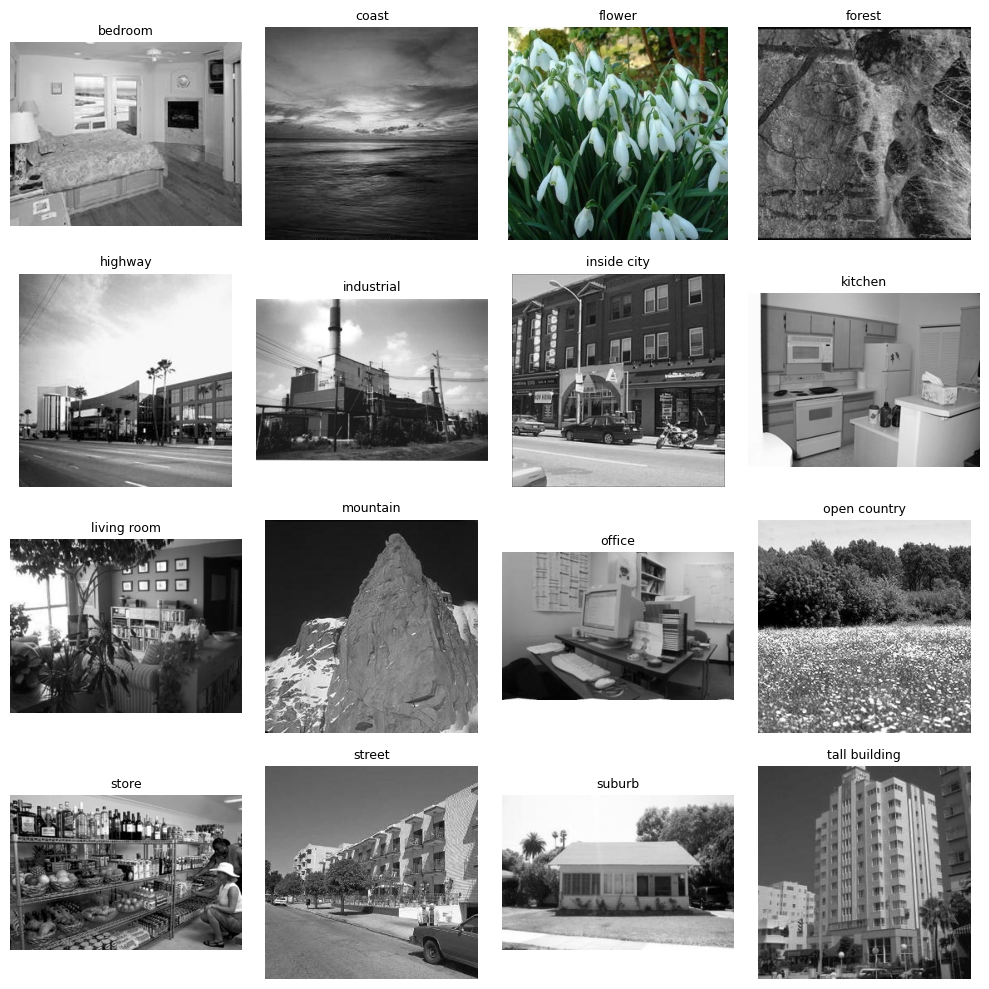

In [13]:
# Visualize the 16 support images (the ONLY labeled training data)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for ax, p, n in zip(axes.ravel(), support_paths, names):
    ax.imshow(load(p)); ax.set_title(n, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Planned approaches (beat the baseline)

**Note:** with one labeled image per class there is no validation set, so accuracies are on the 400-image test set (±~4 points of noise at this size). Settings (templates, temperatures, fusion weight) are fixed a priori and not selected on test accuracy. "Baseline" = 1a, the first iteration of Experiment 1.

| Experiment | Iteration | What changed? | Why did you try it? | Test accuracy | What did you learn? |
|---|---|---|---|---|---|
| **Experiment 1:** zero-shot text classifier (no labeled images) | 1a (baseline) | CLIP ViT-L/14, one prompt: "a photo of a {class}." | Class names alone already carry strong scene information; reference point | -- | -- |
| | 1b | 10-prompt ensemble instead of one prompt | Single prompts are noisy; averaging templates is a cheap fix | -- | -- |
| | 1c | SigLIP SO400M alone, same 10 prompts | Different pretraining data and loss may suit scenes better | -- | -- |
| | 1d | CLIP + SigLIP ensemble (sum of log-probabilities) | The two models make different mistakes | -- | -- |
| **Experiment 2:** one-shot image prototypes | | Cosine similarity to the 16 support images (CLIP, SigLIP, DINOv2) | Use the one labeled image per class | -- | -- |
| **Experiment 3:** ensemble + fusion | | Text evidence (Exp. 1) + image-prototype evidence (Exp. 2), fixed weight | Text and image cues are complementary | -- | -- |
| **Experiment 4:** test-time prompt tuning (TPT) | | Per test image, tune 4 prompt-context vectors by entropy minimisation over 64 augmented views | Adapt to each test image without labels | -- | -- |
| **Experiment 5 (optional):** diffusion variants | | img2img variants generated only from each single support image, averaged into the prototype | More views of the one example | -- | -- |
| **Final model** | | | | -- | -- |

In [24]:
# Results tracker: record() adds / updates one row per experiment and renders a proper markdown table (also saved to results/).
from IPython.display import Markdown, display

RESULTS = []
def record(experiment, what_changed, why, iterations, learned='--', labeled_images=0):
    """iterations = [(label, accuracy), ...] in the order tried; the last one is the experiment's final accuracy."""
    RESULTS[:] = [r for r in RESULTS if r['experiment'] != experiment]
    RESULTS.append({'experiment': experiment, 'what_changed': what_changed, 'why': why,
                    'iterations': [(l, round(a, 4)) for l, a in iterations], 'final_acc': round(iterations[-1][1], 4),
                    'learned': learned, 'labeled_images': labeled_images, 'n_test': len(test_y)})
    show_results()

def show_results():
    base = RESULTS[0]['iterations'][0][1]          # baseline = first iteration of the first experiment
    lines = ['| Experiment | What changed? | Why did you try it? | Labeled imgs | Test accuracy (iteration by iteration) | Final vs baseline | What did you learn? |',
             '|---|---|---|---:|---|---:|---|']
    for r in RESULTS:
        chain = ' → '.join((f"{l} " if l else '') + f"{100 * a:.1f}%" for l, a in r['iterations'])
        lines.append(f"| {r['experiment']} | {r['what_changed']} | {r['why']} | {r['labeled_images']} | "
                     f"{chain} | {100 * (r['final_acc'] - base):+.1f} | {r['learned']} |")
    table = '\n'.join(lines)
    Path('results/results.md').write_text(table + '\n', encoding='utf-8')
    json.dump({'env': ENV, 'baseline_acc': base, 'results': RESULTS}, open('results/results.json', 'w', encoding='utf-8'), indent=1)
    display(Markdown(table))

In [ ]:
# to run after restart
RESULTS[:] = json.load(open('results/results.json', encoding='utf-8'))['results']; show_results()

In [19]:
# Disk cache for expensive results (features, TPT logits), so a restart doesn't lose them.
import hashlib
CACHE = Path('results/cache'); CACHE.mkdir(parents=True, exist_ok=True)

def cached(name, fn, **cfg):
    key = hashlib.md5(json.dumps({'seed': SEED, 'n_test': len(test_paths), 'names': names, **cfg},
                                 sort_keys=True, default=str).encode()).hexdigest()[:8]
    f = CACHE / f'{name}_{key}.pt'
    if f.exists():
        print('loaded from cache:', f.name); return torch.load(f)
    out = fn(); torch.save(out, f); print('saved to cache:', f.name); return out

## 5. Implementations

Each approach below is one sub-section; it loads what it needs, reports its numbers, and adds a row to the table via `record(...)`.

### 5.1 Approach 1: zero-shot text classifier (uses NO labeled images)

Class name -> text prompt -> text embedding; each test image goes to the class whose embedding is closest in the shared image-text space. All backbones are frozen. Features are L2-normalised and flip-averaged (standard test-time augmentation). Models: **CLIP ViT-L/14** (OpenAI) and **SigLIP SO400M/14 @384** (WebLI), via `open_clip`.

In [20]:
CLIP_SPECS = {'clip': ('ViT-L-14', 'openai'), 'siglip': ('ViT-SO400M-14-SigLIP-384', 'webli')}
M = {}
for k, (arch, pre) in CLIP_SPECS.items():
    m, _, prep = open_clip.create_model_and_transforms(arch, pretrained=pre, device=device,
                                                       precision='fp16' if device.type == 'cuda' else 'fp32')
    M[k] = (m.eval(), prep, open_clip.get_tokenizer(arch))
    print('loaded', k, arch, pre)

@torch.no_grad()
def enc_openclip(key, imgs, bs=32, flip=True):
    m, prep, _ = M[key]; out = []
    for i in range(0, len(imgs), bs):
        x = torch.stack([prep(im) for im in imgs[i:i + bs]]).to(device, DTYPE)
        f = m.encode_image(x)
        if flip: f = f + m.encode_image(torch.flip(x, dims=[3]))      # flip-averaged
        out.append(F.normalize(f.float(), dim=-1).cpu())
    return torch.cat(out)

ENC = {'clip': lambda im: enc_openclip('clip', im),        # later approaches add ENC['dino']
       'siglip': lambda im: enc_openclip('siglip', im)}
t0 = time.time()
TF = cached('test_feats', lambda: {k: ENC[k](test_imgs) for k in ENC}, models=list(CLIP_SPECS))   # test features
print({k: tuple(v.shape) for k, v in TF.items()}, f'{time.time() - t0:.0f}s')

C:\Users\omcka\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\omcka\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

C:\Users\omcka\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\omcka\.cache\huggingface\hub\models--timm--vit_large_patch14_clip_224.openai. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\omcka\AppData\Local\Programs\Python\Python312\Lib\site-packages\op

loaded clip ViT-L-14 openai


open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.51GB            

... (3 outputs left out)

C:\Users\omcka\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\omcka\.cache\huggingface\hub\models--timm--ViT-B-16-SigLIP. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

loaded siglip ViT-SO400M-14-SigLIP-384 webli
saved to cache: test_feats_c824f68e.pt
{'clip': (400, 768), 'siglip': (400, 1152)} 93s


In [21]:
TEMPLATES = ['a photo of a {}.', 'a photo of the {}.', 'a picture of a {}.', 'an image of a {}.',
             'a photo of a {} scene.', 'a low resolution photo of a {}.', 'a close-up photo of a {}.',
             'a bright photo of a {}.', 'a cropped photo of a {}.', 'a good photo of a {}.']

@torch.no_grad()
def text_embeds(key, templates):
    m, _, tok = M[key]; embs = []
    for n in names:
        t = tok([tp.format(n) for tp in templates]).to(device)
        e = F.normalize(m.encode_text(t).float(), dim=-1).mean(0)
        embs.append(F.normalize(e, dim=-1).cpu())
    return torch.stack(embs)                                   # [16, d]

def accuracy(logits):
    return (logits.argmax(1) == test_y).float().mean().item()

SCALE = {'clip': 100., 'siglip': 100., 'dino': 50.}           # fixed a priori, never tuned on test
log_probs = lambda cos, k: F.log_softmax(SCALE[k] * cos, dim=-1)

TE1 = {k: text_embeds(k, TEMPLATES[:1]) for k in M}           # single prompt
TE = {k: text_embeds(k, TEMPLATES) for k in M}                # 10-prompt ensemble
L1 = {k: log_probs(TF[k] @ TE1[k].T, k) for k in M}
T_LOG = {k: log_probs(TF[k] @ TE[k].T, k) for k in M}
zs_ens = sum(T_LOG.values())
for k in M:
    print(f'{k:7s} single prompt: {accuracy(L1[k]):.4f} | 10-prompt ensemble: {accuracy(T_LOG[k]):.4f}')
print(f'CLIP+SigLIP ensemble: {accuracy(zs_ens):.4f}')

clip    single prompt: 0.8825 | 10-prompt ensemble: 0.8875
siglip  single prompt: 0.8275 | 10-prompt ensemble: 0.8350
CLIP+SigLIP ensemble: 0.8825


In [25]:
record('Experiment 1: zero-shot text classifier (no labeled images)',
       '1a CLIP ViT-L/14 with one prompt (baseline) → 1b 10-prompt ensemble → 1c SigLIP alone → 1d CLIP + SigLIP ensemble',
       'Class names alone already carry strong scene information; check how far prompts and a second model push it',
       [('1a', accuracy(L1['clip'])), ('1b', accuracy(T_LOG['clip'])), ('1c', accuracy(T_LOG['siglip'])), ('1d', accuracy(zs_ens))])

| Experiment | What changed? | Why did you try it? | Labeled imgs | Test accuracy (iteration by iteration) | Final vs baseline | What did you learn? |
|---|---|---|---:|---|---:|---|
| Experiment 1: zero-shot text classifier (no labeled images) | 1a CLIP ViT-L/14 with one prompt (baseline) → 1b 10-prompt ensemble → 1c SigLIP alone → 1d CLIP + SigLIP ensemble | Class names alone already carry strong scene information; check how far prompts and a second model push it | 0 | 1a 88.2% → 1b 88.8% → 1c 83.5% → 1d 88.2% | +0.0 | -- |

### 5.2 – 5.5 (to be added after Approach 1 has real numbers)

5.2 one-shot image prototypes (Approach 3) · 5.3 ensemble + fusion (Approach 6) · 5.4 test-time prompt tuning (Approach 7) · 5.5 diffusion variants (Approach 10, optional, disclose if used).

## 6. Results

In [ ]:
show_results()

## 7. Observations

_(Fill in after the runs: which approach helped, which did not, why, and how large the gaps are relative to the ±~4-point test-set noise.)_

## 8. Final test evaluation

Run this once after the final configuration has been fixed. In this stage the final configuration is the best zero-shot variant; later stages replace `final_logits`.

In [ ]:
FINAL_NAME = 'CLIP+SigLIP zero-shot ensemble (stage 1)'
final_logits = zs_ens                  # replace in later stages with the fused / TPT logits

final_acc = accuracy(final_logits)
print(f'Final configuration: {FINAL_NAME}')
print(f'Final test accuracy: {final_acc:.4f}  ({int((final_logits.argmax(1) == test_y).sum())}/{len(test_y)})')

In [ ]:
Path('checkpoints').mkdir(exist_ok=True)

torch.save({
    'class_names': names,
    'classes': classes,
    'text_emb': TE,                    # per-model class text embeddings [16, d]
    'image_proto': {},                 # filled in by Approach 3 onwards
    'scale': SCALE,
    'alpha': 1.0,
    'templates': TEMPLATES,
    'clip_specs': CLIP_SPECS,
    'support': [p.as_posix() for p in support_paths],
    'final_config': FINAL_NAME,
    'test_accuracy': final_acc,
    'seed': SEED,
}, 'checkpoints/oneshot_final.pt')

print('Checkpoint saved to checkpoints/oneshot_final.pt')

In [ ]:
# Inference on a single image with the saved checkpoint (zero-shot text + image prototypes, no test-time adaptation).
ck = torch.load('checkpoints/oneshot_final.pt', map_location='cpu')

@torch.no_grad()
def predict(path, topk=3):
    im = [load(path)]
    logp = 0
    for k in ck['text_emb']:
        logp = logp + F.log_softmax(ck['scale'][k] * (ENC[k](im) @ ck['text_emb'][k].T), -1)
    for k in ck['image_proto']:
        logp = logp + ck['alpha'] * F.log_softmax(ck['scale'][k] * (ENC[k](im) @ ck['image_proto'][k].T), -1)
    top = logp.softmax(-1)[0].topk(topk)
    return [(ck['classes'][i], round(v, 4)) for v, i in zip(top.values.tolist(), top.indices.tolist())]

print(test_paths[0], '->', predict(test_paths[0]))

## 9. GitHub and submission requirements

Per the Assignment 3 handout, the repository must contain the codebase, the trained model, inference code and instructions for reproducing the accuracy:

```text
README.md                      reproduction instructions
oneshot.ipynb                  training / adaptation / evaluation code (this notebook)
support/                       the 16 one-shot training images + support_list.json
checkpoints/oneshot_final.pt   trained model (class text embeddings + image prototypes)
results/                       env.json, results.md, results.json
requirements.txt
```

The submission is a **maximum two-page PDF report** with the GitHub link, stating the best test accuracy, the one-shot mechanism (foundation models, observations, test-time adaptation) and a conclusion on balancing model complexity, data availability and compute. **Deadline: November 24, 2026, 11:59 PM ET.**